# Training Glimpse's small models

This notebook runs, in order, everything needed to **specialise the two small models** Glimpse uses on our own domain (children's handwritten maths, reading and science):

1. **Laya** (421M encoder): picks which animation explains an exercise. We train a classification head on its embeddings, compare it with the example vote the app uses today, and save it.
2. **GLM-OCR** (0.9B): reads the camera photo. We build a dataset from the frames the app saved, measure the reading error on photos with known text, check that LoRA training works, and train when enough photos have been reviewed.

The tutor (Qwen3.5-9B) is too big to train in a notebook on a laptop: see `qwen/finetune_mlx.sh`.

**Kernel:** Laya's Python environment, which already has torch, transformers and Laya:
```bash
decide/.venv/bin/python -m pip install jupyterlab ipykernel
decide/.venv/bin/python -m jupyter lab models/train_small_models.ipynb
```
(or in VS Code, pick `decide/.venv` as the kernel). Everything runs on an Apple Silicon Mac (MPS), an NVIDIA GPU or, slowly, a CPU.

## 0. Packages and paths

In [1]:
%pip install -q -r ../decide/requirements.txt -r glm-ocr/requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, os, sys, time
from collections import Counter

MODELS = os.path.abspath('.')             # the notebook runs from models/
ROOT = os.path.dirname(MODELS)
for p in ('laya', 'glm-ocr'):
    sys.path.insert(0, os.path.join(MODELS, p))

import torch, transformers, peft
import train_head as laya_train          # models/laya/train_head.py
import build_dataset as ocr_data         # models/glm-ocr/build_dataset.py
import finetune_lora as ocr              # models/glm-ocr/finetune_lora.py
from examples import KINDS               # decide/examples.py: the animation kinds, every subject

device, _ = ocr.device_and_dtype()
print(f"torch {torch.__version__}, transformers {transformers.__version__}, peft {peft.__version__}, device: {device}")
print(f"{len(KINDS)} kinds: {', '.join(KINDS)}")

/Users/chenghengli/Desktop/hackathon/glimpse/decide/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1122 07:40:26.201000 99864 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


torch 2.15.0, transformers 5.24.0, peft 0.22.0, device: mps
37 kinds: count, number_line, columns, groups, area_model, sharing, fractions, percent, order_ops, powers, mean, balance, inequality, pythagoras, pairs, quadratic, system, graph, trig, limit, derivative, area, chance, combinations, tree, syllables, phonics, spelling, plural, sentence, units, speed, density, circuit, states, food_chain, none


## 1. Laya: which animation fits

### 1.1 The training examples
Generated by `decide/examples.py` (varied numbers, words and notations, as the OCR and as typed text), plus what the app learned while running (`decide/learned.jsonl`). To specialise for a new domain, add a generator there, or pass your own labelled lines with `extra=`.

In [3]:
rows = laya_train.training_rows()
counts = laya_train.count_by_kind(rows)
print(f"{len(rows)} examples")
for kind, n in counts.items():
    example = next(t for t, k in rows if k == kind)
    print(f"  {kind:14} {n:4}   e.g. {example[:60]!r}")

5124 examples
  count           200   e.g. '6 + 3 ='
  number_line     200   e.g. '416 + 94 ='
  columns          80   e.g. '1886 + 329 ='
  groups          201   e.g. '3 \\times 10 ='
  area_model       80   e.g. '32 \\times 30 ='
  sharing          80   e.g. '120 \\div 10 ='
  fractions       160   e.g. '\\frac{1}{7} + \\frac{5}{2} ='
  percent          80   e.g. '50\\% of 40'
  order_ops        82   e.g. '2 + 2 \\times 4 ='
  powers           82   e.g. '3^6 ='
  mean             60   e.g. 'mean of 10, 5, 9'
  balance         243   e.g. '5x + 2 = 12'
  inequality       81   e.g. '8x + 2 > 13'
  pythagoras       80   e.g. '3^2 + 4^2 = c^2'
  pairs           160   e.g. '1 + 2 + ... + 20 ='
  quadratic        82   e.g. 'x^2 - 2x - 3 = 0'
  system           60   e.g. '2x + 5y = 18, 1x - 1y = 0'
  graph           120   e.g. 'y = 3 - x'
  trig            100   e.g. '\\tan 150^\\circ'
  limit            60   e.g. '\\lim_{x \\to 1} \\frac{x^2 - 1}{x - 1}'
  derivative       80   e.g. '\\frac

### 1.2 Laya reads them (embeddings)

In [4]:
agent, embed = laya_train.load_laya()
X, y = laya_train.embed_rows(embed, rows)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 3131.01it/s]

/Users/chenghengli/Desktop/hackathon/glimpse/decide/.venv/lib/python3.15/site-packages/laya/agent.py:546: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return super().__call__(*args, **kwargs)


Laya loaded on mps in 0.8s


5124 examples embedded in 15.4s (1024 dimensions)


### 1.3 Train the head
A logistic-regression layer over the 1024-dimension embeddings: one weight per (dimension, kind). Every kind counts as much as the others, however many examples it has.

In [5]:
t = time.time()
head = laya_train.train_head(X, y, epochs=300, lr=0.05, l2=1e-4, scale=20.0)
print(f"trained in {time.time() - t:.1f}s")
print("epoch  loss    train accuracy")
for epoch, loss, acc in head['history'][::2]:
    print(f"{epoch:5}  {loss:.4f}  {acc:.3f}")

  epoch  100  loss 0.0057  train accuracy 0.999


  epoch  200  loss 0.0079  train accuracy 0.999


  epoch  300  loss 0.0098  train accuracy 0.999
trained in 0.8s
epoch  loss    train accuracy
   50  0.0299  0.995
  150  0.0064  0.999
  250  0.0091  0.999


### 1.4 Evaluate on exercises it never saw
`decide/eval.py`: held-out exercises written differently from the examples, and edge cases (lines with nothing to animate, notation variants). Compared with the example vote (k-NN) the app's service uses.

In [6]:
ABSTAIN = 0.35
deciders = {'trained head': laya_train.head_decider(embed, head, ABSTAIN), 'example vote (k-NN)': laya_train.knn_decider(embed, X, y)}
scores = laya_train.evaluate(deciders)
for method, sets in scores.items():
    print(method)
    for name, (right, total, wrong) in sets.items():
        print(f"  {name:20} {right}/{total}")
        for w in wrong:
            print(f"      {w['text'][:55]!r}: expected {w['expected']}, got {w['got']}")

trained head
  held-out exercises   56/57
      '$1 \\times 100 = 100$': expected groups, got area_model
  edge cases           24/26
      'What time is it?': expected none, got graph
      '21/11/2026': expected none, got pythagoras
  reading and science  20/20
example vote (k-NN)
  held-out exercises   54/57
      '$7001 - 2456 =$': expected columns, got number_line
      'Name: Noor': expected none, got spelling
      'Find the area of the triangle': expected none, got units
  edge cases           22/26
      'What time is it?': expected none, got states
      'Factors of 12: 1, 2, 3, 4, 6, 12': expected none, got mean
      'Find the perimeter of a rectangle 5 cm by 3 cm': expected none, got density
      '21/11/2026': expected none, got groups
  reading and science  20/20


### 1.5 Try it on your own lines

In [7]:
tries = [
    'Sam has 3 bags with 4 apples in each. How many apples?',
    'What is 15% of 80?',
    'lim x->0 sin(2x)/x',
    'Split the word elephant into syllables',
    'Convert 3.5 km to metres',
    'A car drives 120 km in 2 hours. What is its speed?',
    'What time is it?',
]
head_decide, knn_decide = deciders['trained head'], deciders['example vote (k-NN)']
for t in tries:
    (hk, hp), (kk, kp) = head_decide(t), knn_decide(t)
    print(f"{t[:55]:57} head: {hk:13} ({hp:.2f})   k-NN: {kk:13} ({kp:.2f})")

Sam has 3 bags with 4 apples in each. How many apples?    head: sentence      (0.35)   k-NN: speed         (0.86)
What is 15% of 80?                                        head: percent       (0.98)   k-NN: percent       (1.00)
lim x->0 sin(2x)/x                                        head: area          (0.91)   k-NN: area          (0.63)
Split the word elephant into syllables                    head: syllables     (1.00)   k-NN: syllables     (1.00)
Convert 3.5 km to metres                                  head: units         (0.97)   k-NN: units         (1.00)
A car drives 120 km in 2 hours. What is its speed?        head: speed         (1.00)   k-NN: speed         (1.00)


What time is it?                                          head: graph         (0.59)   k-NN: states        (0.27)


### 1.6 Specialise further: your own labelled lines
Teachers' corrections, or a new domain, as JSON lines `{"text": ..., "kind": ...}` (any kind in `KINDS`). Retrain with them and compare.

In [8]:
extra = os.path.join(MODELS, 'laya', 'out', 'extra-example.jsonl')
os.makedirs(os.path.dirname(extra), exist_ok=True)
with open(extra, 'w') as f:
    for text, kind in [('Tom shares 18 sweets between 3 friends', 'sharing'), ('Half of the pizza plus a quarter', 'fractions'),
                       ('Is 7/8 bigger than 3/4?', 'fractions'), ('Average of 4, 8 and 9', 'mean')]:
        f.write(json.dumps({'text': text, 'kind': kind}) + '\n')
rows2 = laya_train.training_rows(extra)
X2, y2 = laya_train.embed_rows(embed, rows2)
head2 = laya_train.train_head(X2, y2, epochs=300, log=None)
scores2 = laya_train.evaluate({'head + extra': laya_train.head_decider(embed, head2, ABSTAIN)})
for name, (right, total, _) in scores2['head + extra'].items():
    print(f"head + extra lines, {name}: {right}/{total}")

5128 examples embedded in 15.6s (1024 dimensions)


head + extra lines, held-out exercises: 56/57
head + extra lines, edge cases: 24/26
head + extra lines, reading and science: 20/20


### 1.7 Save the head

In [9]:
report = laya_train.save_head(head, ABSTAIN, scores, len(rows))
print(json.dumps(report['scores'], indent=1))

saved models/laya/out/head.npz and report.json
{
 "trained head: held-out exercises": "56/57",
 "trained head: edge cases": "24/26",
 "trained head: reading and science": "20/20",
 "example vote (k-NN): held-out exercises": "54/57",
 "example vote (k-NN): edge cases": "22/26",
 "example vote (k-NN): reading and science": "20/20"
}


## 2. GLM-OCR: reading handwriting

### 2.1 The dataset
When the engine runs locally it saves every camera frame with GLM-OCR's reading (`debug-frames/engine/`). Those readings are a first draft of the labels: **review them** before training (`python3 models/glm-ocr/review.py` in a terminal: it opens each photo and lets you fix the text).

In [10]:
rows_ocr = ocr_data.update_index()
reviewed = [r for r in rows_ocr if r.get('reviewed')]
print(f"{len(rows_ocr)} photos, {len(reviewed)} reviewed")
for r in rows_ocr[-3:]:
    print(f"  {r['image']}: {r['text'][:70]!r}")

246 photos (21 new), 0 reviewed -> models/glm-ocr/data/ocr.jsonl
246 photos, 0 reviewed
  images/2026-11-22T06-35-25-358Z.jpg: '$3/4 + 1/2 = 4/6$\n$2/5 + 1/3 = 3/8$'
  images/2026-11-22T06-35-35-492Z.jpg: '$3/4 + 1/2 = 4/6$\n$2/5 + 1/3 = 3/8$'
  images/2026-11-22T06-35-55-325Z.jpg: '$3/4 + 1/2 = 4/6$\n$2/5 + 1/3 = 3/8$'


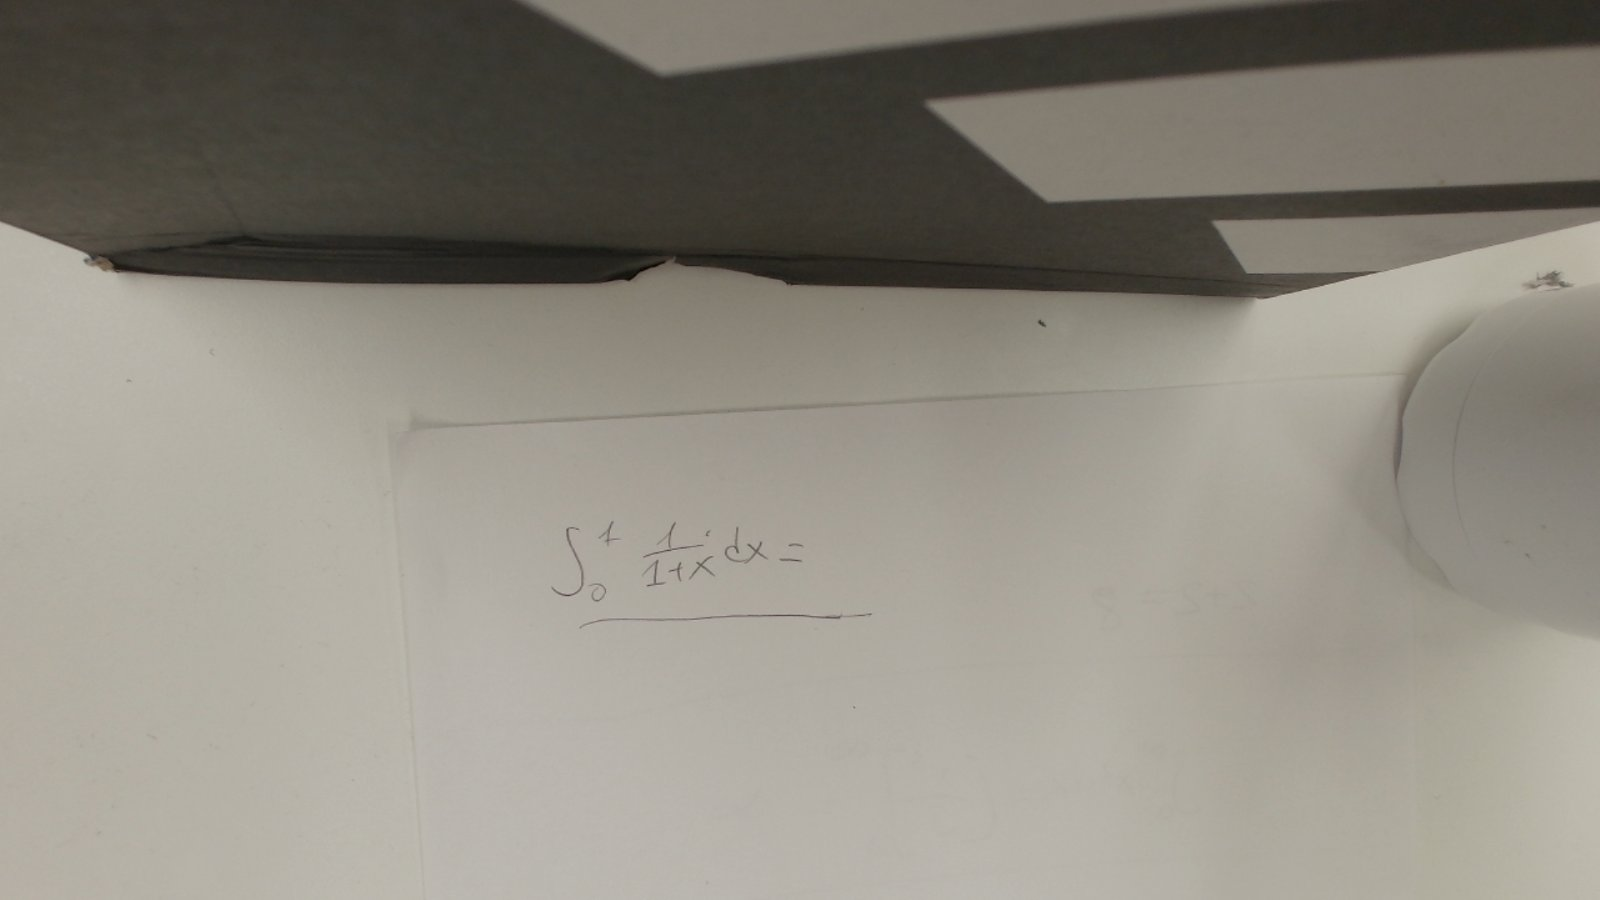

\int_0^1 \frac{1}{1+x} dx =


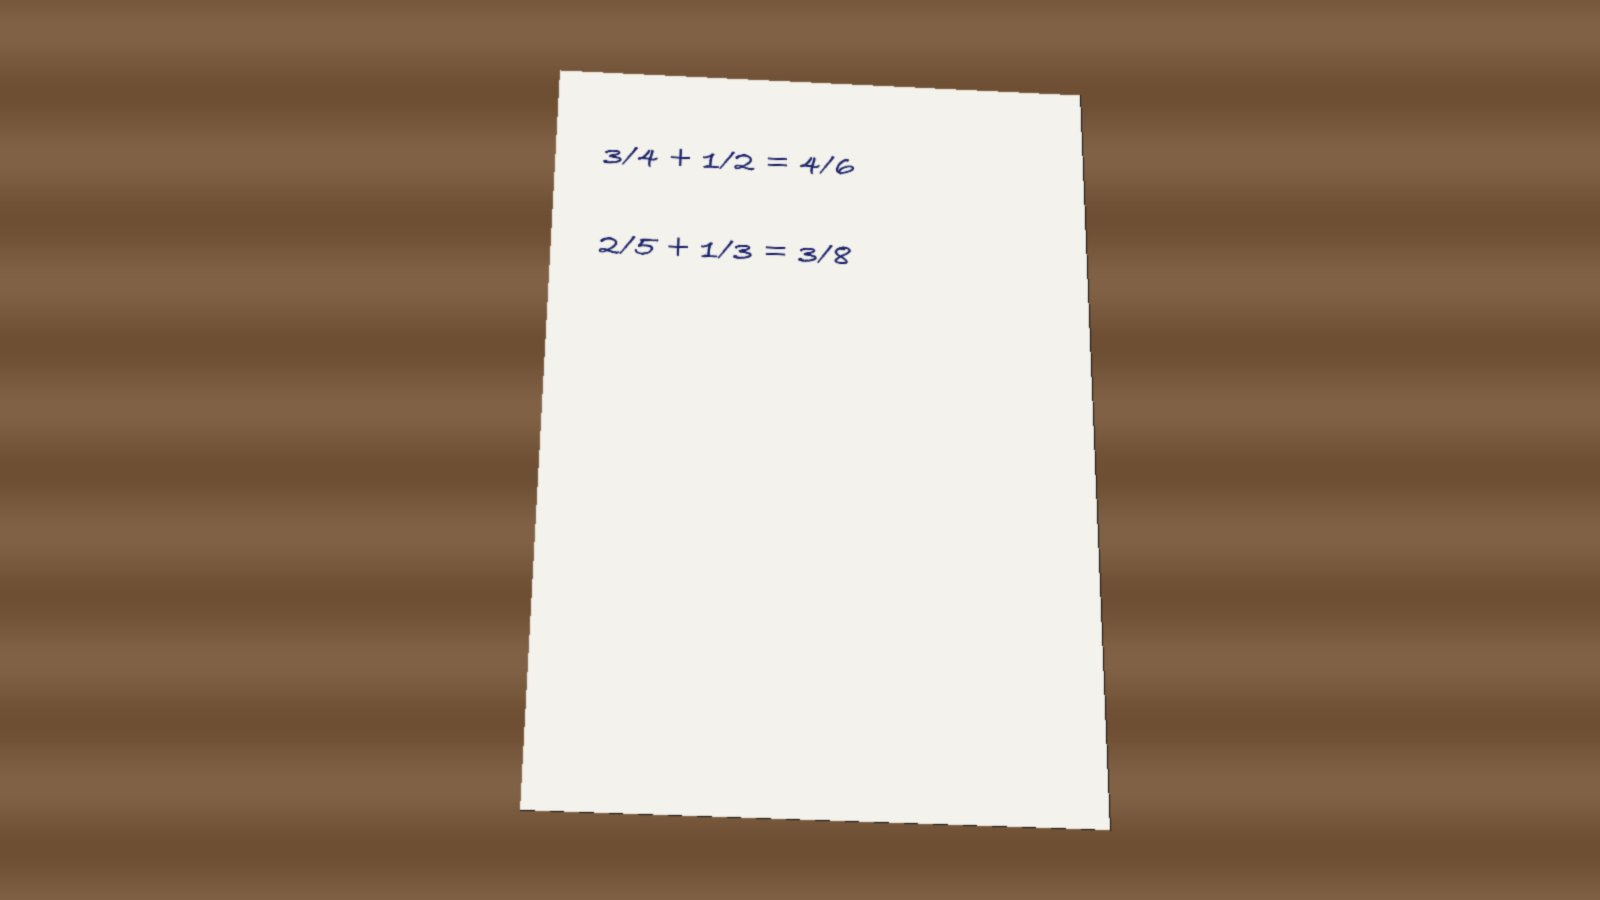

3/4 + 1/2 = 4/6 / 2/5 + 1/3 = 3/8


In [11]:
# what a training pair looks like: a photo and its text (the test photos; your own frames stay out of the notebook)
from IPython.display import Image, display
for name, text in [('integral.jpg', '\\int_0^1 \\frac{1}{1+x} dx ='), ('fractions.jpg', '3/4 + 1/2 = 4/6 / 2/5 + 1/3 = 3/8')]:
    display(Image(filename=os.path.join(ROOT, 'test', 'fixtures', name), width=420))
    print(text)

### 2.2 GLM-OCR before any training
The **gold set** (`glm-ocr/gold.jsonl`): photos whose text we know for sure (the test photos). The character error rate (CER) is the share of characters to fix (0 = perfect). Add your reviewed photos to it as they come.

In [12]:
gold = [json.loads(l) for l in open(os.path.join(MODELS, 'glm-ocr', 'gold.jsonl'))]
for g in gold:
    g['images'] = [os.path.join(ROOT, g['images'][0])]
model, processor = ocr.load()
t = time.time()
print(f"CER on the gold set: {ocr.evaluate(model, processor, gold, data='', show=len(gold)):.3f}  ({time.time() - t:.1f}s)")

Loading weights:   0%|          | 0/510 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 510/510 [00:00<00:00, 10729.86it/s]

zai-org/GLM-OCR on mps, 1.11B parameters


  expected: '\\int_0^1 \\frac{1}{1+x} dx ='
  read:     '$\\int_0^1 \\frac{1}{1+x} dx =$'  (CER 0.00)


  expected: '3/4 + 1/2 = 4/6\n2/5 + 1/3 = 3/8'
  read:     '3/4 + 1/2 = 4/6\n\n2/5 + 1/3 = 3/8'  (CER 0.00)
CER on the gold set: 0.000  (2.5s)


### 2.3 Check that training works (one step, no saving)
The loss on the gold photos (low: the labels match what GLM-OCR already reads), then LoRA adapters on the language model only (the base model and the vision encoder stay frozen: 0.7% of the weights are trained), and one forward and backward pass.

In [13]:
train_rows, valid_rows = ocr_data.split(rows_ocr, use_all=not reviewed)   # unreviewed only to try the pipeline
# the loss on a photo we know: low means the labels line up with what GLM-OCR already does
with torch.no_grad():
    for g in gold:
        inputs = ocr.inputs_for(model, processor, g['images'][0], g['messages'][1]['content'])
        print(f"loss on {os.path.basename(g['images'][0])}: {ocr.loss_of(model, inputs).item():.3f}")
# LoRA on the language model (the base stays frozen), then one forward + backward step
lora_loss, lora = ocr.check_step(model, processor, train_rows[0])
print(f"one training step works (loss {lora_loss:.3f} on an unreviewed reading)")

train.jsonl: 210, valid.jsonl: 36 (images are relative to models/glm-ocr/data/)


loss on integral.jpg: 0.812


loss on fractions.jpg: 0.231
trainable params: 7,471,104 || all params: 1,114,876,928 || trainable%: 0.6701


807 tokens, 192 adapter tensors got a gradient
one training step works (loss 0.551 on an unreviewed reading)


### 2.4 Train (once enough photos are reviewed)
Training on GLM-OCR's own unreviewed readings would teach it its own mistakes, so this only runs with at least 50 reviewed photos. It keeps the result only if the error rate on the reviewed validation photos goes down.

In [14]:
MIN_REVIEWED = 50
if len(reviewed) >= MIN_REVIEWED:
    train_rows, valid_rows = ocr_data.split(rows_ocr)
    before = ocr.evaluate(lora, processor, valid_rows)
    ocr.train(lora, processor, train_rows, epochs=3, lr=1e-4)
    after = ocr.evaluate(lora, processor, valid_rows, show=3)
    print(f"CER on valid: {before:.3f} -> {after:.3f}")
    if after < before:
        ocr.save(lora, processor)
else:
    print(f"{len(reviewed)} reviewed photos: review at least {MIN_REVIEWED} with review.py, then run this cell again.")

0 reviewed photos: review at least 50 with review.py, then run this cell again.


## 3. Using the results

- **Laya's head** (`laya/out/head.npz`): load it in `decide/laya_service.py` next to the example bank and mix its probabilities into the decision; check with `decide/eval.py`.
- **GLM-OCR** (`glm-ocr/out/merged`): serve it with an OpenAI-compatible server (vLLM, or `mlx_vlm.server`) and set `OCR_BASE_URL` / `OCR_MODEL` in `.env.local`.
- **The tutor**: `qwen/build_dataset.py` + `qwen/finetune_mlx.sh` (MLX, outside this notebook).

More in `models/README.md`.